# Opdracht : Voorspel herseninfarct


## Teamgegevens

* **teamnaam in kaggle:** 
* **Teamleden met kaggle gebruikersnamen:**
  * Jakub Rebelski (jakubrebelski1)
  * Arda Bagci (Muhammed Arda Bağcı)
  * Vito van Herwerden (Vito van Herwerden)



## Inleiding

In dit project treden wij op als junior data scientists voor MedPredict, een medisch technologiebedrijf dat zorginstellingen ondersteunt bij het vroegtijdig signaleren van gezondheidsrisico’s. Ons doel is om een machine-learningmodel te ontwikkelen dat betrouwbaar voorspelt of een patiënt een verhoogd risico loopt op een herseninfarct (stroke), gebaseerd op geanonimiseerde persoons-, leefstijl- en medische gegevens.

Een sterk voorspellend model kan zorgprofessionals gericht helpen bij preventie en patiëntopvolging. Omdat dit een medische toepassing betreft waarbij verkeerde voorspellingen (zoals onterecht alarm of juist het missen van een risicopatiënt) directe gevolgen hebben, vereist deze opdracht een uiterst kritische blik op de data, de gemaakte keuzes en de uiteindelijke betrouwbaarheid van het model.

Dit project vormt tevens onze inzending voor de Kaggle-competitie van de opleiding Applied Data Science & AI. In dit notebook documenteren we ons volledige proces: van de initiële Exploratieve Data Analyse (EDA) tot het trainen, evalueren en verantwoorden van ons best presterende model.

## Imports
Hier laden we alle benodigde Python-bibliotheken in die we gebruiken voor de data-analyse en het trainen van de modellen die we later nodig gaan hebben.

In [12]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import f1_score, classification_report, confusion_matrix



# Data inladen
Voor dit project maken we gebruik van drie bestanden die voor de Kaggle-competitie beschikbaar zijn gesteld. We laden deze direct aan het begin in:

* **`train_ml.csv`**: De trainingsdataset. Deze bevat de patiëntgegevens inclusief de doelvariabele (wel of geen herseninfarct). We gebruiken deze data voor de Exploratieve Data Analyse (EDA) en om de modellen te trainen.
* **`test_ml.csv`**: De testdataset. Deze bevat dezelfde patiëntgegevens, maar zónder de uitkomst. Ons uiteindelijke model gaat voor deze groep patiënten de voorspellingen maken.
* **`sample_submission.csv`**: Een voorbeeldbestand dat exact het format toont waarin we onze definitieve voorspellingen op Kaggle moeten indienen.

In [13]:
df = pd.read_csv('train_ml.csv')
df_test = pd.read_csv('test_ml.csv')
df_submission = pd.read_csv('sample_submission.csv')

# Hier controleren we of de data correct is ingeladen
df.head()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,52709,30.0,0,0,63.60,33.3,False,True,False,True,...,False,True,False,False,True,False,False,False,True,0
1,72295,75.0,1,0,215.17,48.0,True,False,False,False,...,False,False,True,False,True,False,False,True,False,0
2,26451,15.0,0,0,135.22,19.0,False,True,False,True,...,False,True,False,False,True,False,False,True,False,0
3,65210,47.0,0,0,64.89,28.2,False,True,False,False,...,False,False,True,False,False,True,False,True,False,0
4,69299,49.0,0,0,222.34,28.8,False,True,False,False,...,False,False,True,False,True,False,True,False,False,0


# 1. Opdracht 1: Exploratieve Data Analyse

De dataset bevat patiëntgegevens waarbij categorische variabelen (zoals geslacht en soort werk) al zijn omgezet in *dummy-variabelen*. Hierbij wordt een tekstwaarde opgesplitst in meerdere kolommen met een 1 (ja) of een 0 (nee), omdat machine learning modellen uitsluitend met numerieke data kunnen rekenen. Hieronder volgt de verklaring van alle 22 kolommen:

## 1.1 Uitleg van colommen

In [14]:
# Hier kijken we welke colommen er in de dataset zitten
list(df.columns)

['id',
 'age',
 'hypertension',
 'heart_disease',
 'avg_glucose_level',
 'bmi',
 'gender_Female',
 'gender_Male',
 'gender_Other',
 'ever_married_No',
 'ever_married_Yes',
 'work_type_Govt_job',
 'work_type_Never_worked',
 'work_type_Private',
 'work_type_Self-employed',
 'work_type_children',
 'Residence_type_Rural',
 'Residence_type_Urban',
 'smoking_status_formerly smoked',
 'smoking_status_never smoked',
 'smoking_status_smokes',
 'stroke']

De dataset bevat patiëntgegevens waarbij categorische variabelen (zoals geslacht en soort werk) al zijn omgezet in *dummy-variabelen*. Hierbij wordt een tekstwaarde opgesplitst in meerdere kolommen met een 1 (ja) of een 0 (nee), omdat machine learning modellen uitsluitend met numerieke data kunnen rekenen. Hieronder volgt de uitleg van alle 22 kolommen:

| Kolomnaam | Uitleg | Type Variabele |
| :--- | :--- | :--- |
| **id** | Unieke identificatiecode van de patiënt. | Identificatie |
| **age** | De leeftijd van de patiënt in jaren. | Numeriek |
| **hypertension** | Geeft aan of de patiënt een hoge bloeddruk heeft (0 = nee, 1 = ja). | Binair |
| **heart_disease** | Geeft aan of de patiënt een hartaandoening heeft (0 = nee, 1 = ja). | Binair |
| **avg_glucose_level** | De gemiddelde suikerspiegel in het bloed van de patiënt. | Numeriek |
| **bmi** | Body Mass Index, een maat voor de verhouding tussen gewicht en lengte. | Numeriek |
| **gender_Female** | Dummy: Patiënt is vrouw (0 = nee, 1 = ja). | Dummy |
| **gender_Male** | Dummy: Patiënt is man (0 = nee, 1 = ja). | Dummy |
| **gender_Other** | Dummy: Patiënt heeft een ander geslacht (0 = nee, 1 = ja). | Dummy |
| **ever_married_No** | Dummy: Patiënt is nooit getrouwd geweest. | Dummy |
| **ever_married_Yes** | Dummy: Patiënt is ooit getrouwd (geweest). | Dummy |
| **work_type_Govt_job** | Dummy: Patiënt werkt voor de overheid. | Dummy |
| **work_type_Never_worked** | Dummy: Patiënt heeft nooit betaald werk gehad. | Dummy |
| **work_type_Private** | Dummy: Patiënt werkt in de private sector. | Dummy |
| **work_type_Self-employed**| Dummy: Patiënt werkt als zelfstandige / ondernemer. | Dummy |
| **work_type_children** | Dummy: Patiënt valt onder de leeftijdscategorie 'kind'. | Dummy |
| **Residence_type_Rural** | Dummy: Patiënt woont op het platteland (rural). | Dummy |
| **Residence_type_Urban** | Dummy: Patiënt woont in een stedelijk gebied (urban). | Dummy |
| **smoking_status_formerly smoked** | Dummy: Patiënt heeft in het verleden gerookt. | Dummy |
| **smoking_status_never smoked** | Dummy: Patiënt heeft nog nooit gerookt. | Dummy |
| **smoking_status_smokes** | Dummy: Patiënt is een actieve roker. | Dummy |
| **stroke** | **De doelvariabele (target).** Heeft de patiënt een herseninfarct gehad? (0 = nee, 1 = ja). | Binair (Target) |

## 1.2 Vereisten voor Machine Learning met Scikit-Learn
Om modellen te kunnen trainen met Scikit-Learn, moet de dataset aan twee strikte voorwaarden voldoen:
1. **Volledig numeriek:** Scikit-Learn algoritmes kunnen uitsluitend rekenen met getallen (integers of floats), niet met tekst (strings). Doordat de tekstuele categorieën in deze dataset al zijn omgezet naar dummy-variabelen (1 en 0), hebben we hier al een grote stap in gemaakt.
2. **Geen missende waarden (NaN):** De modellen crashen als er lege cellen in de data staan. We moeten dus controleren of de dataset helemaal compleet is, en anders de missende data verwijderen of opvullen (imputeren).

## 1.3 Datatypes, missende waarden en basisstatistieken
Om te onderzoeken in hoeverre onze dataset aan bovenstaande eisen voldoet, schrijven we een zelf-gedefinieerde functie. Dit houdt onze code overzichtelijk en herbruikbaar.

In [15]:
def inspecteer_data(dataset):
    """
    Functie om een overzicht te geven van de datatypes, 
    het aantal missende waarden en de basisstatistieken van een dataset.
    """
    print("--- 1. Datatypes ---")
    # info() print automatisch de datatypes en het aantal niet-lege waarden
    dataset.info()
    
    print("\n--- 2. Aantal missende waarden per kolom ---")
    missende_waarden = dataset.isnull().sum()
    # Toon alleen de kolommen waar daadwerkelijk data ontbreekt
    print(missende_waarden[missende_waarden > 0]) 
    
    print("\n--- 3. Basisstatistieken ---")
    # describe() geeft statistieken zoals gemiddelde, min, max en standaarddeviatie
    return dataset.describe()

# Voer de functie uit op onze trainingsdata
inspecteer_data(df)

--- 1. Datatypes ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33550 entries, 0 to 33549
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              33550 non-null  int64  
 1   age                             33550 non-null  float64
 2   hypertension                    33550 non-null  int64  
 3   heart_disease                   33550 non-null  int64  
 4   avg_glucose_level               33550 non-null  float64
 5   bmi                             33550 non-null  float64
 6   gender_Female                   33550 non-null  bool   
 7   gender_Male                     33550 non-null  bool   
 8   gender_Other                    33550 non-null  bool   
 9   ever_married_No                 33550 non-null  bool   
 10  ever_married_Yes                33550 non-null  bool   
 11  work_type_Govt_job              33550 non-null  bool   
 12  work_type_N

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000
mean,36746.393353,41.815312,0.088137,0.043040,103.587081,28.601216,0.015410
std,20906.519131,22.477423,0.283498,0.202951,42.127396,7.782248,0.123178
min,1.000000,0.080000,0.000000,0.000000,55.010000,10.100000,0.000000
25%,18763.250000,24.000000,0.000000,0.000000,77.460000,23.300000,0.000000
50%,36862.000000,43.000000,0.000000,0.000000,91.320000,27.700000,0.000000
75%,54757.500000,59.000000,0.000000,0.000000,111.437500,32.800000,0.000000
max,72943.000000,82.000000,1.000000,1.000000,281.590000,97.600000,1.000000


## 1.4 Conclusie inspectie en Data Opschonen
Uit de bovenstaande output blijkt dat de dataset voldoet aan de eisen voor Scikit-Learn: er zijn geen missende waarden en alle kolommen hebben een werkbaar datatype (`int`, `float`, `bool`). 

Tijdens het kritisch bekijken van de data zijn ons echter twee dingen opgevallen die we moeten opschonen:
1. **De `id` kolom:** Deze heeft geen voorspellende waarde. Als we deze in de trainingsdata laten staan, kan het model hier onterecht patronen in proberen te vinden (overfitting). We verwijderen deze kolom voor de training.
2. **De "Dummy Variable Trap":** De data is voorbewerkt met dummy-variabelen, maar dit zorgt voor dubbele informatie (multicollineariteit). Zo is `ever_married_No` het exacte tegenovergestelde van `ever_married_Yes`, en geldt hetzelfde voor het type woonomgeving (`Rural`/`Urban`). Daarnaast zagen we een extreme negatieve correlatie tussen de geslachten. Om te voorkomen dat modellen zoals Logistic Regression wiskundig moeite krijgen met deze dubbele informatie, verwijderen we per categorie één overtollige kolom. We droppen daarom `ever_married_No`, `Residence_type_Rural` en `gender_Female`.

In [16]:
def verwijder_kolommen(dataset, kolommen_om_te_verwijderen):
    """
    Verwijdert een opgegeven lijst met kolommen uit de dataset.
    Checkt met een 'if'-statement of de kolom wel echt in de dataset zit.
    """
    df_clean = dataset.copy()
    
    for kolom in kolommen_om_te_verwijderen:
        # Check eerst of de kolom in de dataset bestaat
        if kolom in df_clean.columns:
            df_clean = df_clean.drop(columns=[kolom])
            print(f" Kolom verwijderd: {kolom}")
        else:
            print(f"Let op: Kolom '{kolom}' was al verwijderd of bestaat niet.")
            
    return df_clean

# 1. Bepaal zelf welke kolommen weg moeten
overbodige_kolommen = ['id', 'ever_married_No', 'Residence_type_Rural','gender_Female']

# 2. Roep de herbruikbare functie aan op de trainingsdata
df = verwijder_kolommen(df, overbodige_kolommen)

 Kolom verwijderd: id
 Kolom verwijderd: ever_married_No
 Kolom verwijderd: Residence_type_Rural
 Kolom verwijderd: gender_Female


## 1.5 Relaties tussen variabelen en de doelvariabele
Om te begrijpen welke factoren de grootste invloed hebben op het wel of niet krijgen van een herseninfarct (`stroke`), visualiseren we de data. We maken hiervoor gebruik van een zelf-gedefinieerde functie die boxplots genereert. Hiermee kunnen we de verdeling van numerieke variabelen (zoals leeftijd en glucose) vergelijken tussen patiënten mét (1) en zónder (0) herseninfarct.

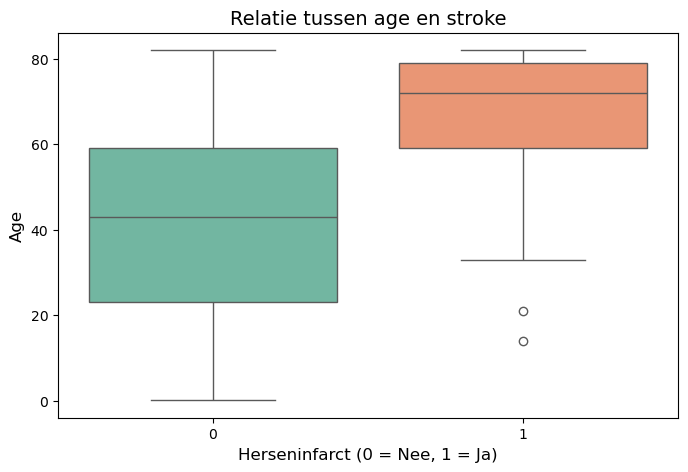

In [17]:
def plot_numeriek_vs_target(dataset, kolom, target='stroke'):
    """
    Genereert een boxplot om de verdeling van een numerieke variabele 
    te vergelijken tussen de twee groepen van de doelvariabele (target).
    """
    plt.figure(figsize=(8, 5))
    
    # Gebruik hue en legend=False om de FutureWarning te voorkomen
    sns.boxplot(data=dataset, x=target, y=kolom, hue=target, palette='Set2', legend=False)
    
    plt.title(f'Relatie tussen {kolom} en {target}', fontsize=14)
    plt.xlabel('Herseninfarct (0 = Nee, 1 = Ja)', fontsize=12)
    plt.ylabel(kolom.capitalize(), fontsize=12)
    
    plt.show()

# Roep de functie aan voor leeftijd (age)
plot_numeriek_vs_target(df, 'age')

### Conclusie: Leeftijd (Age)
Uit de bovenstaande boxplot blijkt dat er een duidelijk verschil in leeftijd is tussen de twee groepen. De patiënten die een herseninfarct hebben gehad (groep 1) zijn gemiddeld aanzienlijk ouder (de mediaan ligt rond de 70 jaar) dan de patiënten zonder herseninfarct (mediaan rond de 43 jaar). Leeftijd lijkt dus een sterke indicatie te geven voor de kans op een herseninfarct.

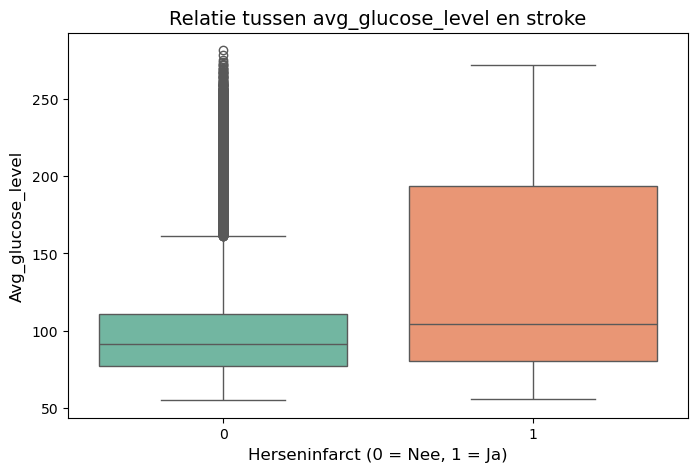

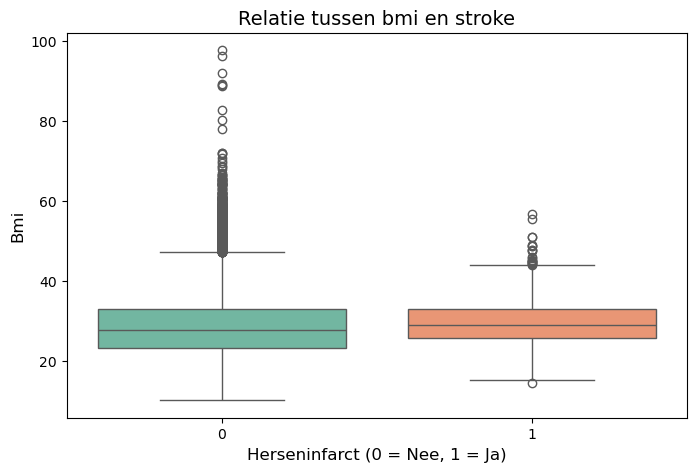

In [18]:
# Analyseer de overige twee numerieke variabelen
plot_numeriek_vs_target(df, 'avg_glucose_level')
plot_numeriek_vs_target(df, 'bmi')

### Conclusie: Gemiddeld Suikerniveau (Avg_glucose_level)
Bij het gemiddelde suikerniveau zien we dat de spreiding in de groep met een herseninfarct (groep 1) veel groter is naar de hogere waarden toe. De mediaan ligt ook iets hoger. Dit suggereert dat hogere glucosewaarden (boven de 100-150) vaker voorkomen bij patiënten die een herseninfarct hebben gehad, wat wijst op een mogelijke relatie.

### Conclusie: Body Mass Index (BMI)
Kijken we naar het BMI, dan zien we nauwelijks verschil tussen de twee groepen. De medianen van beide boxplots liggen vrijwel op dezelfde lijn (rond de 28) en de spreiding van de middelste 50% van de data is nagenoeg identiek. Op basis van deze visuele inspectie lijkt BMI geen erg sterke onderscheidende voorspeller voor een herseninfarct te zijn.

## 1.6 Correlatiematrix (Heatmap)
Om de samenhang tussen alle variabelen te analyseren, berekenen we de correlatiematrix. We tonen specifiek de correlatie van alle kenmerken met de doelvariabele (`stroke`). Dit geeft direct wiskundig inzicht in welke factoren de sterkste positieve of negatieve relatie hebben met het optreden van een herseninfarct

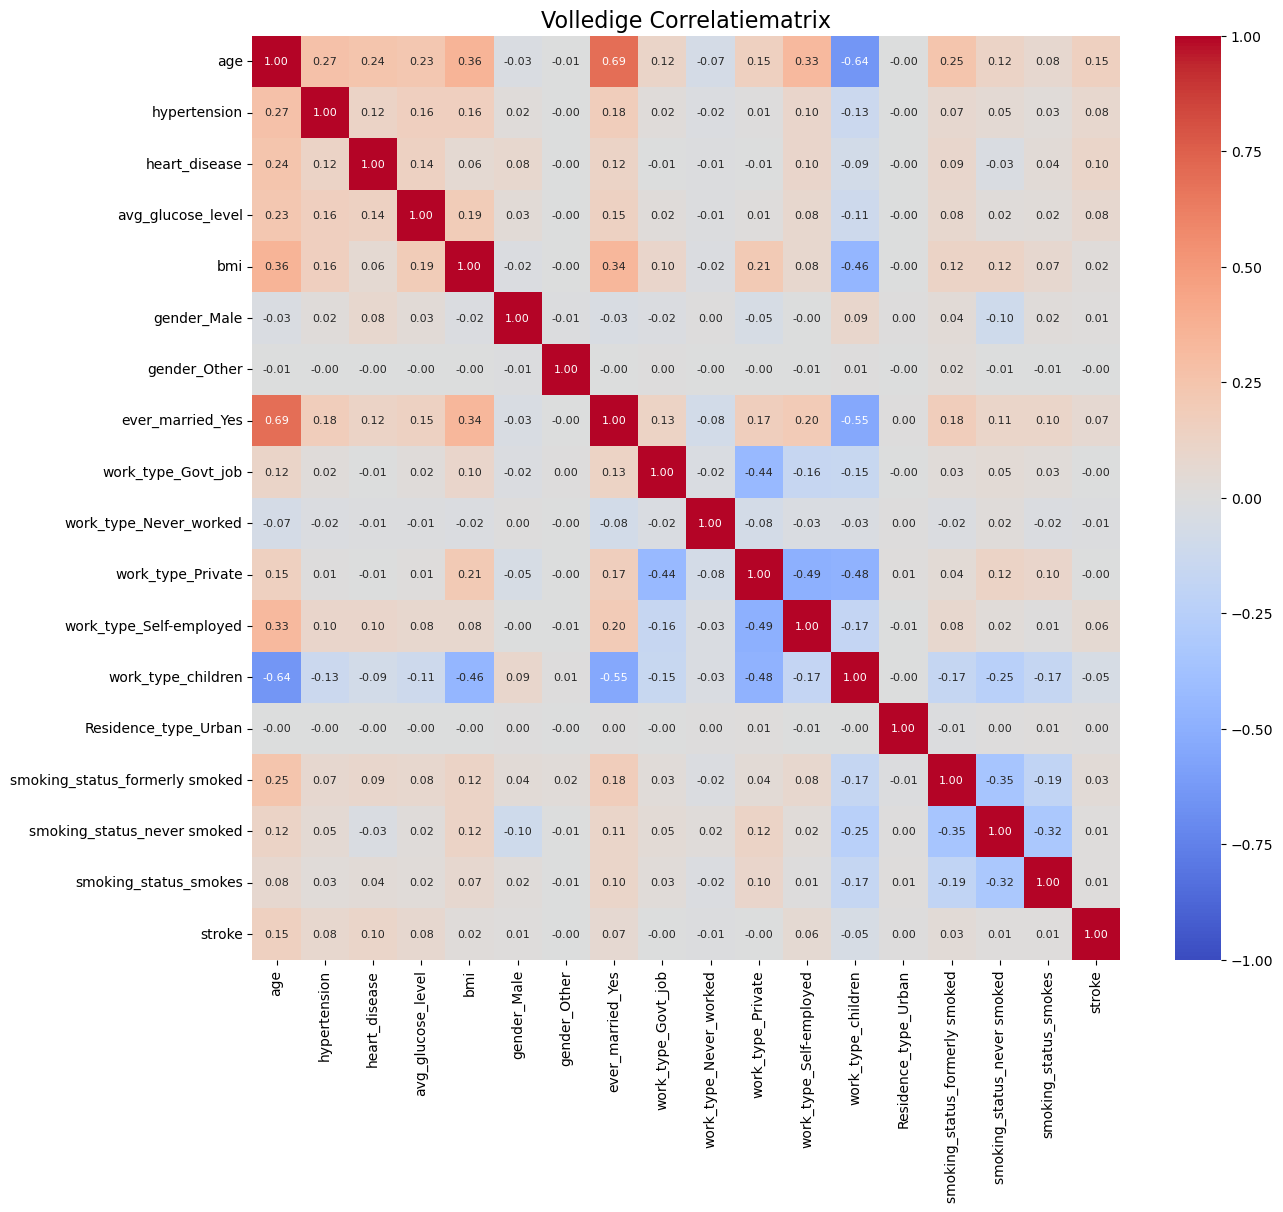

In [19]:
def plot_volledige_correlatiematrix(dataset):
    """
    Berekent de volledige correlatiematrix en genereert een vierkante heatmap 
    van alle variabelen in de dataset.
    """
    correlaties = dataset.corr()
    
    # Maak de grafiek groot genoeg voor alle 20+ kolommen
    plt.figure(figsize=(14, 12))
    
    
    # Genereer de heatmap
    sns.heatmap(correlaties, 
                annot=True,          # Laat de correlatiegetallen zien
                fmt=".2f",           # Twee decimalen
                cmap='coolwarm',     # Rood = positief, Blauw = negatief
                vmin=-1, vmax=1, 
                annot_kws={"size": 8}) # Maak het lettertype iets kleiner voor de leesbaarheid
    
    plt.title('Volledige Correlatiematrix', fontsize=16)
    plt.show()

# Roep de functie aan
plot_volledige_correlatiematrix(df)

### Conclusie: Correlatiematrix (Opgeschoond)
Uit de vernieuwde heatmap komen de volgende belangrijke observaties naar voren:

1. **Beperkte lineaire correlaties met de doelvariabele (`stroke`):** Geen enkele variabele toont een extreem sterke lineaire correlatie met een herseninfarct[cite: 5]. Leeftijd (`age`) heeft de hoogste voorspellende waarde met een correlatie van 0.15[cite: 5]. Daarna volgen hartaandoeningen (`heart_disease`, 0.10), het gemiddelde glucosepeil (`avg_glucose_level`, 0.08) en hoge bloeddruk (`hypertension`, 0.08)[cite: 5]. 
2. **Succesvolle aanpak van Multicollineariteit:** De eerdere extreme correlatie van -1.00 tussen de geslachten is nu volledig verdwenen[cite: 5]. Dit bevestigt dat onze stap om `gender_Female` en de andere overtollige dummy-variabelen te verwijderen, succesvol was in het oplossen van de 'Dummy Variable Trap'. Het model krijgt nu geen dubbele informatie meer.
3. **Natuurlijke verbanden in de data:** Binnen de onafhankelijke variabelen zien we nog wel enkele logische verbanden. Zo is er een sterke positieve correlatie (0.69) tussen leeftijd (`age`) en ooit getrouwd zijn (`ever_married_Yes`)[cite: 5]. Daarnaast is er een sterke negatieve correlatie (-0.64) tussen leeftijd en de werk-categorie kinderen (`work_type_children`)[cite: 5], wat volkomen verklaarbaar is.